# Mpox: is a sporadic genome different from a sustained one?

---

### The question

The mentor's keywords: **host, transmission, sporadic, sustained**. Mpox has no usable host contrast (almost every genome is human), but it does have the other three: some genomes are one-off spillovers or dead-end cases (**sporadic**), others sit in long chains of person-to-person spread (**sustained**). The earlier notebooks compared groups the nomenclature had named; this one defines sporadic and sustained **from the genomes themselves**, without using the mutation spectrum, and then asks whether the **APOBEC3 share of recent mutations** differs.

### How sporadic and sustained are defined

1. For every pair of genomes, count the substitutions that differ, only at positions readable in **both** (so gaps do not look like differences).
2. Join genomes that differ by **5 or fewer** substitutions into **clusters** (chains of near-identical genomes).
3. A cluster of **1-2 genomes** is *sporadic-looking* (no onward transmission seen in the data), a cluster of **10 or more spanning at least half a year** is *sustained-looking*, the rest are in between.

This uses only the genome differences and the collection dates, not the APOBEC3 count. Samples: all clade I genomes with at most 5% unreadable bases (511) and a subsample of clade IIb (1,516: all lineage-A genomes plus 1,300 others).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.abspath("../.."))
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. How many clusters

In [2]:
cl = pd.read_csv("results/mpox_transmission_clusters.tsv", sep="\t")
t = cl.groupby(["dataset", "class"]).agg(clusters=("cluster", "size"), genomes=("size", "sum"),
                                         median_span_years=("span_years", "median")).round(2)
t

clusters  genomes  median_span_years
dataset   class                                             
clade I   intermediate        36      217               0.08
          sporadic           185      220               0.00
          sustained            4       74               1.01
clade IIb intermediate        36      203               0.20
          sporadic           230      271               0.00
          sustained            6     1042               3.27

In [3]:
print("Sustained-looking clusters:")
cl[cl["class"] == "sustained"][["dataset", "size", "span_years", "countries", "groups"]].round(2).sort_values(["dataset", "size"], ascending=False).to_string(index=False)

Sustained-looking clusters:


'  dataset  size  span_years  countries         groups\nclade IIb   943        1.94         32        IIb B-J\nclade IIb    34        1.02          2        IIb B-J\nclade IIb    21        0.81          2        IIb B-J\nclade IIb    17        6.95          4  IIb lineage A\nclade IIb    16        8.32          3  IIb lineage A\nclade IIb    11        4.61          1  IIb lineage A\n  clade I    28        0.70          3      Ib sh2023\n  clade I    20        1.33          1      Ib sh2023\n  clade I    15        1.36          1 Ia no outbreak\n  clade I    11        0.60          1 Ia no outbreak'

**Reading it.** Most clusters are 1-2 genomes (185 of 225 in clade I, 230 of 272 in clade IIb). **Only 4 clade I and 6 clade IIb clusters qualify as sustained-looking**, so any comparison on that class alone rests on very few clusters. The largest is the 2022 global outbreak, a single cluster of 943 sampled genomes from 32 countries over 1.9 years.

## 2. The APOBEC3 share by class

Pooled APOBEC3 share of "recent" mutations (those relative to the nearest tree neighbour), genomes with at most 1% unreadable bases and at most 30 recent mutations. Intervals resample **whole clusters**, because genomes in a cluster are related.

In [4]:
s = pd.read_csv("results/mpox_transmission_share.tsv", sep="\t")
s["class"] = pd.Categorical(s["class"], ["sporadic", "intermediate", "sustained"])
s.sort_values(["dataset", "class"])[["dataset", "class", "genomes", "clusters", "recent mutations", "APOBEC3 share", "ci_lo", "ci_hi"]].round(3)

,dataset,class,genomes,clusters,recent mutations,APOBEC3 share,ci_lo,ci_hi
1,clade I,sporadic,140,119,849,0.278,0.220,0.337
0,clade I,intermediate,148,32,656,0.157,0.087,0.207
2,clade I,sustained,38,4,153,0.641,0.158,0.709
4,clade IIb,sporadic,261,220,1673,0.607,0.548,0.669
3,clade IIb,intermediate,203,36,513,0.832,0.753,0.891
5,clade IIb,sustained,1042,6,1656,0.801,0.429,0.850


**Reading it.** At the 5-substitution threshold the **sustained-looking clusters have a higher share than the sporadic-looking ones** in both clades (clade I: 0.64 against 0.28; clade IIb: 0.80 against 0.61). But the sustained intervals are wide (0.16-0.71 and 0.43-0.85) because they rest on 4 and 6 clusters, and the **intermediate class does not fit a line** in clade I (0.16, the lowest). So the three-class comparison is suggestive, not firm. The next two sections look at it more finely.

## 3. By cluster size, inside each group

Genome-weighted share, binned by the size of the cluster each genome sits in.

In [5]:
g = pd.read_csv("data/processed/Mpox/Mpox_transmission_genomes.tsv", sep="\t")
x = g[(g.ambig_frac <= 0.01) & (g.priv <= 30)].copy()
x["size_bin"] = pd.cut(x["size"], [0, 1, 2, 4, 9, 10**6], labels=["1 (singleton)", "2", "3-4", "5-9", "10+"])
tb = x.groupby(["group", "size_bin"], observed=True).agg(genomes=("priv", "size"), clusters=("cluster", "nunique"),
                                                         mutations=("priv", "sum"), apobec=("priv_apobec", "sum"))
tb["APOBEC3 share"] = (tb.apobec / tb.mutations).round(3)
tb[["genomes", "clusters", "mutations", "APOBEC3 share"]]

genomes  clusters  mutations  APOBEC3 share
group          size_bin                                                  
IIb B-J        1 (singleton)      135       135       1050          0.577
               2                   52        26        261          0.743
               3-4                 31         9        111          0.811
               5-9                 63        10        180          0.767
               10+               1019         5       1660          0.815
IIb lineage A  1 (singleton)       44        44        228          0.417
               2                   30        15        134          0.896
               3-4                 36        10         68          0.779
               5-9                 22         4         61          0.984
               10+                 74         4         89          0.674
Ia no outbreak 1 (singleton)       52        52        266          0.094
               2                   36        21        120          0.133
               3-4                 43        19        138          0.130
               5-9                 50        10        164          0.091
               10+                 16         2         19          0.158
Ia sh2024      1 (singleton)        3         3         10          0.200
               2                    3         2          8          0.125
               10+                 39         1        291          0.172
Ib sh2023      1 (singleton)       38        38        368          0.391
               2                    8         4         77          0.623
               5-9                  9         1         31          0.387
               10+                 29         3        166          0.620

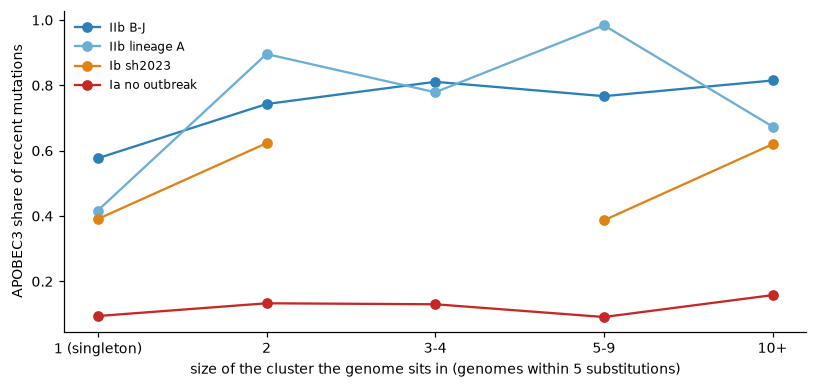

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
cols = {"IIb B-J": "#2C7FB8", "IIb lineage A": "#6BAED6", "Ib sh2023": "#E08214", "Ia no outbreak": "#C62824"}
bins = ["1 (singleton)", "2", "3-4", "5-9", "10+"]
for grp, c in cols.items():
    t = tb.loc[grp]["APOBEC3 share"].reindex(bins)
    ax.plot(range(len(bins)), t.values, marker="o", color=c, label=grp)
ax.set_xticks(range(len(bins))); ax.set_xticklabels(bins)
ax.set_xlabel("size of the cluster the genome sits in (genomes within 5 substitutions)")
ax.set_ylabel("APOBEC3 share of recent mutations"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig("results/figures/mpox_share_by_cluster_size.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.** In the two **clade IIb** groups the share **jumps once a genome has any relative** (singleton 0.58 in the 2022 outbreak families, 0.42 in lineage A, then 0.67-0.98 for clusters of 2 and above) and stays high. **Ib** shows a smaller step (0.39 for singletons, about 0.6 for clusters of 2 and of 10+). **Ia stays flat near 0.1 at every size.**

## 4. The direct test: singletons against genomes in clusters

Singletons are genomes with **no relative within 5 substitutions in our data**: the clearest "sporadic-looking" case. For each group, the pooled share for singletons against genomes in clusters of 2 or more, with the difference and an interval from resampling clusters on each side.

In [7]:
rng = np.random.default_rng(0)
def boot(df, n=3000):
    c = df.groupby("cluster").agg(a=("priv_apobec", "sum"), t=("priv", "sum"))
    a, t = c.a.values, c.t.values
    idx = rng.integers(0, len(c), (n, len(c)))
    return a[idx].sum(1) / np.maximum(t[idx].sum(1), 1), a.sum() / t.sum()
rows = []
for grp in ["IIb B-J", "IIb lineage A", "Ib sh2023", "Ia no outbreak"]:
    t = x[x.group == grp]; s_, c_ = t[t["size"] == 1], t[t["size"] >= 2]
    bs, ps = boot(s_); bc, pc = boot(c_); d = bc - bs
    rows.append({"group": grp, "singleton genomes": len(s_), "share (singletons)": ps,
                 "genomes in clusters": len(c_), "clusters": c_.cluster.nunique(), "share (clustered)": pc,
                 "difference": pc - ps, "95% interval": f"{np.percentile(d, 2.5):.2f} to {np.percentile(d, 97.5):.2f}",
                 "excludes zero": bool(np.percentile(d, 2.5) > 0 or np.percentile(d, 97.5) < 0)})
res = pd.DataFrame(rows).set_index("group")
res.to_csv("results/mpox_singleton_vs_cluster.tsv", sep="\t")
res.round(3)

,singleton genomes,share (singletons),genomes in clusters,clusters,share (clustered),difference,95% interval,excludes zero
group,,,,,,,,
IIb B-J,135,0.577,1165,50,0.802,0.225,0.13 to 0.29,True
IIb lineage A,44,0.417,162,33,0.832,0.416,0.15 to 0.60,True
Ib sh2023,38,0.391,46,8,0.595,0.204,-0.02 to 0.34,False
Ia no outbreak,52,0.094,145,52,0.118,0.024,-0.03 to 0.08,False


**Reading it.**

| Group | Singleton | In a cluster | Difference | Clear? |
|---|---|---|---|---|
| IIb 2022 outbreak families | 0.58 | 0.80 | **+0.23** (0.13 to 0.29) | **yes** |
| IIb lineage A (pre-2022) | 0.42 | 0.83 | **+0.42** (0.15 to 0.60) | **yes** |
| Ib outbreak (sh2023) | 0.39 | 0.60 | +0.20 (-0.02 to 0.34) | borderline |
| Ia, no outbreak | 0.09 | 0.12 | +0.02 (-0.03 to 0.08) | no |

**In the human-adapted clade (IIb) genomes with no onward transmission seen carry a clearly lower APOBEC3 share than genomes in chains.** Ib points the same way but the interval touches zero. **Ia shows nothing** because its share is low everywhere (about 0.1), so even its larger clusters do not look human-adapted by this marker.

## 5. Robustness

The three-class table was rerun with the distance threshold at 3, 5 and 10 substitutions and with stricter or looser quality filters.

In [8]:
sv = pd.read_csv("results/mpox_transmission_sensitivity.tsv", sep="\t")
p = sv.pivot_table(index=["dataset", "T", "filter"], columns="class", values="APOBEC3 share").round(2)
p[["sporadic", "intermediate", "sustained"]]

class                             sporadic  intermediate  sustained
dataset   T  filter                                                
clade I   3  <=1% N, <=15 recent      0.27          0.17       0.73
             <=1% N, <=30 recent      0.27          0.17       0.73
             <=5% N, <=30 recent      0.24          0.20       0.72
          5  <=1% N, <=15 recent      0.29          0.16       0.64
             <=1% N, <=30 recent      0.28          0.16       0.64
             <=5% N, <=30 recent      0.24          0.15       0.67
          10 <=1% N, <=15 recent      0.34          0.26       0.24
             <=1% N, <=30 recent      0.32          0.23       0.24
             <=5% N, <=30 recent      0.30          0.18       0.25
clade IIb 3  <=1% N, <=15 recent      0.75          0.86       0.81
             <=1% N, <=30 recent      0.65          0.86       0.81
             <=5% N, <=30 recent      0.65          0.86       0.81
          5  <=1% N, <=15 recent      0.74          0.83       0.80
             <=1% N, <=30 recent      0.61          0.83       0.80
             <=5% N, <=30 recent      0.61          0.83       0.80
          10 <=1% N, <=15 recent      0.65          0.93       0.79
             <=1% N, <=30 recent      0.49          0.81       0.78
             <=5% N, <=30 recent      0.49          0.81       0.78

**Reading it.** In clade IIb the sporadic class is the lowest in **every one of the nine settings** (0.49-0.75 against 0.78-0.93 for intermediate and sustained), so that result is stable. In clade I it is **not**: the sustained class is highest at thresholds 3 and 5 (0.64-0.73) but drops to 0.24 at threshold 10, and the intermediate class is lowest in all nine. The clade I three-class result should not be relied on; for clade I only the within-Ib singleton comparison in section 4 is informative, and it is borderline.

## 6. What this means

| Question (mentor's keywords) | Answer |
|---|---|
| **Host**: is there a host contrast? | **No.** Nearly all genomes are human (the rest are unknown host, plus two animal genomes). |
| **Sporadic versus sustained**: does a marker separate them? | **Yes in clade IIb**, with a clear interval in both groups; **suggestive in Ib**; **absent in Ia**. |
| **Transmission**: what is the marker? | The APOBEC3 share of recent mutations, not GC or CpG (those do not differ). |

**Why this is a result and not just the published signature.** The published work (O'Toole 2023) uses the APOBEC3 signature to say a *lineage* spreads between people. Here the unit is the **genome**: genomes with no relatives in the data look less APOBEC3-driven than genomes in chains, within the same lineage family, using a classification that does not use the spectrum.

### Limits

- **Singletons carry more noise.** A genome with no close relative has no neighbour to confirm its private mutations, so sequencing errors (not APOBEC3-type) count against it. The 1% and 30-mutation filters help but do not remove this.
- **Sampling density.** A singleton may simply be in a thinly sampled part of the tree; "no relatives in our data" is not "no onward transmission".
- **Few sustained clusters** (4 and 6), so the three-class estimate is imprecise.
- **Clade Ia.** The marker does not separate anything, which either means Ia spread is not APOBEC3-driven, or that the DRC genomes are too noisy for this measure.

### Next

1. Replace "recent mutations against the Nextclade tree" with mutations from our own tree (IQ-TREE and ancestral reconstruction), to check the singleton effect is not a tree-sampling artefact.
2. Test the same two-step idea (cluster structure, then mutation spectrum) on another host-switching virus once the metadata is exported: SARS-CoV-2 or H5N1.